# VigiaVia — Detecção de buracos em vias públicas com visão computacional

**FIAP · Global Solution 2026.2 · CitizenTech · Applied Computer Vision** (Profs. Arnaldo Viana e Paulo Rodrigues)

| Integrante | RM |
|---|---|
| Deivison Pertel | 550803 |
| Eduardo Akira Murata | 98713 |
| Wesley Souza de Oliveira | 97874 |

Este notebook documenta o componente de **Visão** do MVP VigiaVia: dados → treino customizado (transfer learning) →
avaliação → análise de vieses → tempo real (rastreamento + realidade aumentada) → exportação ONNX → integração via API.
Os passos pesados (download do dataset e treino) são executados pelos scripts em `scripts/`; aqui carregamos os
artefatos gerados e rodamos demonstrações ao vivo, com as saídas salvas.

In [1]:
import json, os, sys, platform
from pathlib import Path
import cv2, numpy as np, pandas as pd, torch, ultralytics
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
DATA = Path(os.getenv("VIGIAVIA_DATA", RAIZ / "datasets" / "vigiavia-rdd2022"))
RES = RAIZ / "resultados"
print("Python", platform.python_version(), "| PyTorch", torch.__version__, "| Ultralytics", ultralytics.__version__,
      "| OpenCV", cv2.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "não disponível")
print("Dataset:", DATA.exists() and "ok", "| imagens de teste:", len(list((DATA / "images" / "test").glob("*.jpg"))))

Python 3.13.9 | PyTorch 2.11.0+cu128 | Ultralytics 8.4.202 | OpenCV 5.0.0
GPU: NVIDIA GeForce RTX 3070
Dataset: ok | imagens de teste: 622


## 1. Dados — RDD2022 oficial (classe D40, "buraco")

* **Fonte:** RDD2022 — *Multi-National Road Damage Dataset* (Arya et al., 2022), release oficial do CRDDC'2022
  (figshare, doi:10.6084/m9.figshare.21431547), anotações Pascal VOC com o **nome** da classe.
* **Auditoria de rótulos** (`scripts/01b_auditar_rotulos.py`): uma redistribuição em YOLO no Hugging Face rotulava
  como "pothole" faixas apagadas (D44), faixas de pedestre (D43) e bueiros (D50) — os buracos (D40) tinham sido
  descartados. Detectamos isso inspecionando recortes antes de treinar e trocamos para a release oficial.
* **Seleção** (`scripts/01_preparar_dataset.py`): imagens de nível de rua de Japão, Índia, China (moto), República
  Tcheca e EUA; todas as imagens com buraco + 25% de imagens **sem** buraco como negativas; split 70/15/15 em
  **blocos de 20 quadros consecutivos** (evita quadros quase idênticos em treino e teste). Só os trechos necessários
  do zip de 13 GB são baixados (HTTP Range).

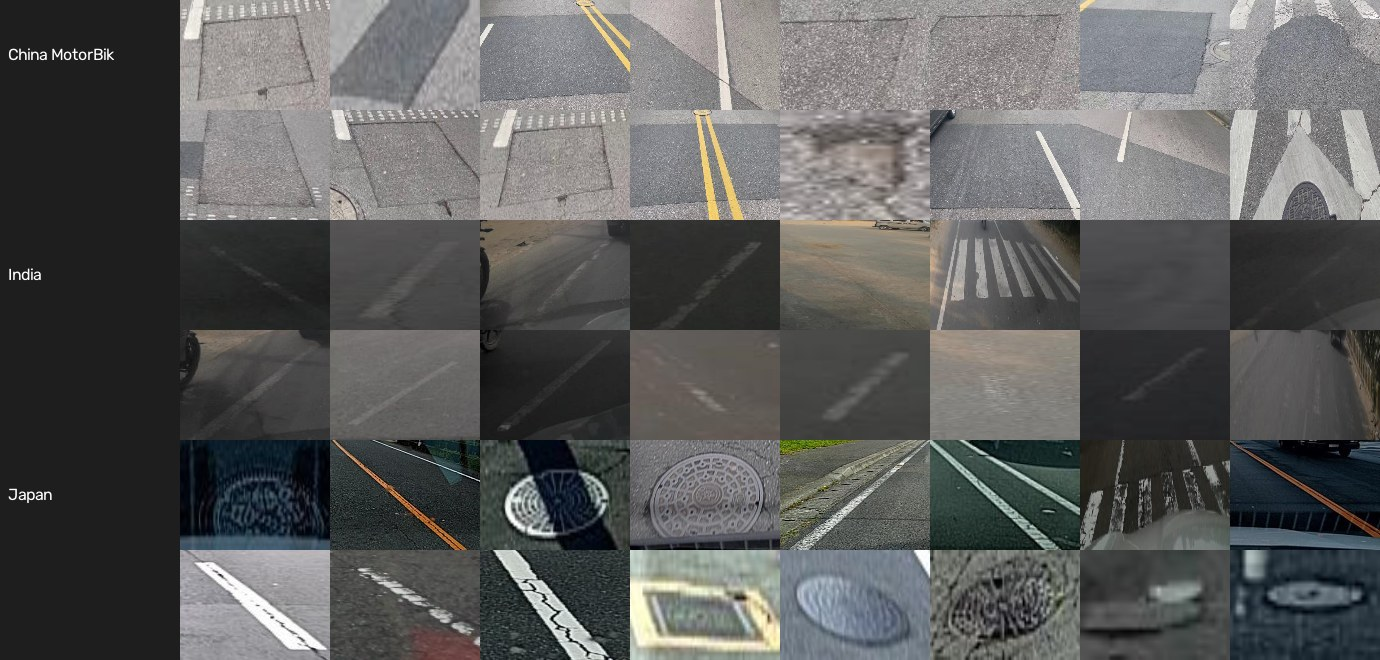

**Acima:** rótulos 'pothole' da redistribuição (incorretos). **Abaixo:** classe D40 da release oficial.

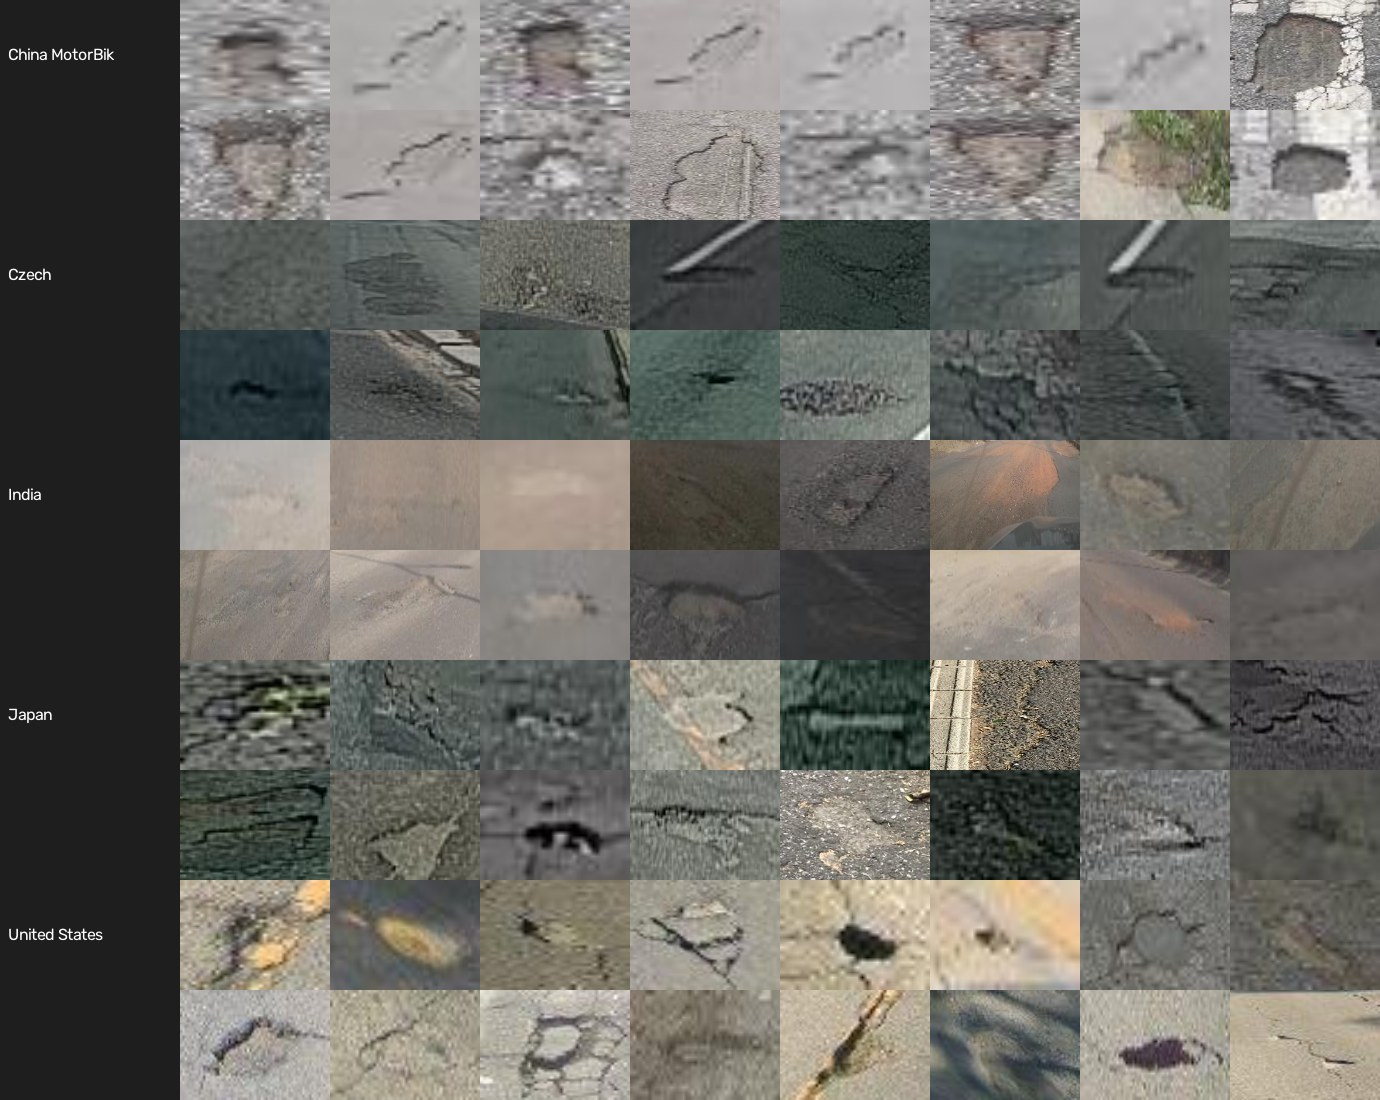

In [2]:
display(Image(filename=str(RES / "auditoria_rotulos_redistribuicao_hf.jpg"), width=900))
display(Markdown("**Acima:** rótulos 'pothole' da redistribuição (incorretos). **Abaixo:** classe D40 da release oficial."))
display(Image(filename=str(RES / "auditoria_rotulos_oficial.jpg"), width=900))

In [3]:
stats = json.loads((RES / "dataset_stats.json").read_text(encoding="utf-8"))
man = pd.read_csv(DATA / "manifest.csv")
tab = man.assign(com_buraco=man.n_buracos > 0).groupby(["split", "pais"]).agg(
    imagens=("arquivo", "count"), com_buraco=("com_buraco", "sum"), buracos=("n_buracos", "sum"))
display(tab)
print("Totais:", {k: v["imagens"] for k, v in stats["splits"].items()}, "| caixas de buraco:",
      sum(v["caixas_buraco"] for v in stats["splits"].values()))

imagens  com_buraco  buracos
split pais                                         
test  China_MotorBike       22          19       30
      Czech                 42          34       46
      India                274         204      463
      Japan                258         209      345
      United_States         26          23       26
train China_MotorBike      154         120      167
      Czech                131         107      133
      India               1377        1118     2318
      Japan               1194         959     1534
      United_States        104          81       97
val   China_MotorBike       29          25       38
      Czech                 19          13       18
      India                261         208      406
      Japan                286         222      364
      United_States         15          12       12

Totais: {'train': 2960, 'test': 622, 'val': 610} | caixas de buraco: 5997


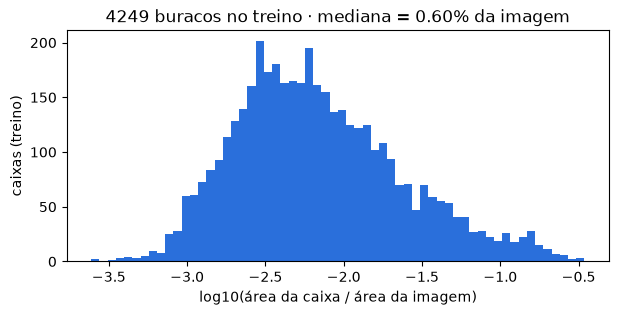

In [4]:
# Tamanho relativo das caixas (fração da imagem) — buracos são, em geral, objetos pequenos
areas = []
for lbl in (DATA / "labels" / "train").glob("*.txt"):
    for l in lbl.read_text().splitlines():
        if l.strip():
            _, _, _, w, h = map(float, l.split()); areas.append(w * h)
areas = np.array(areas)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(areas), bins=60, color="#2a6fdb")
ax.set_xlabel("log10(área da caixa / área da imagem)"); ax.set_ylabel("caixas (treino)")
ax.set_title(f"{len(areas)} buracos no treino · mediana = {np.median(areas)*100:.2f}% da imagem")
plt.show()

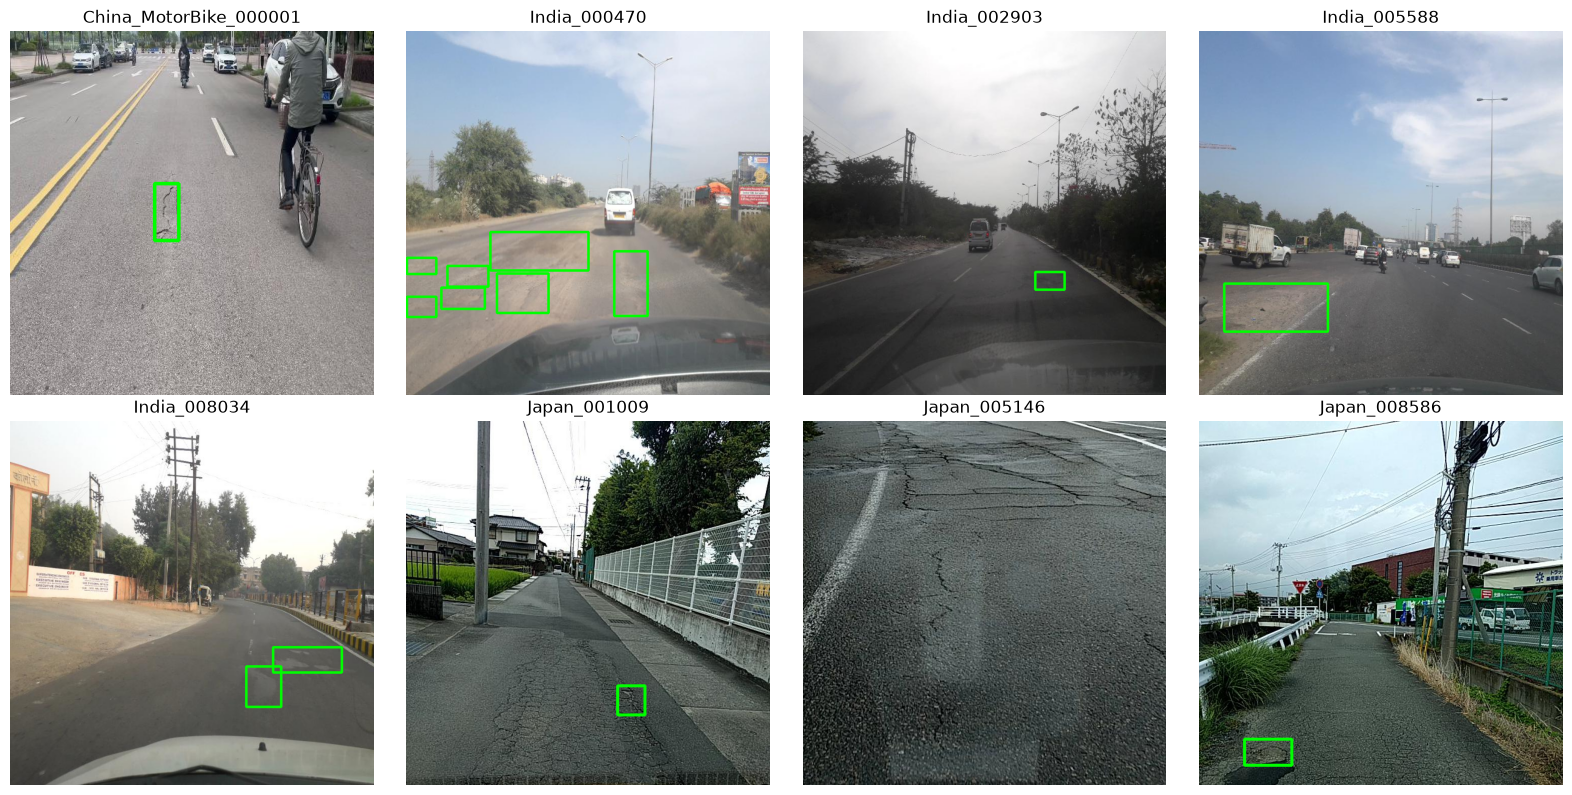

In [5]:
# Amostra do treino com as anotações (caixas verdes)
amostra = sorted((DATA / "images" / "train").glob("*.jpg"))[::350][:8]
fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for ax, p in zip(axs.ravel(), amostra):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    for l in (DATA / "labels" / "train" / (p.stem + ".txt")).read_text().splitlines():
        _, cx, cy, bw, bh = map(float, l.split())
        cv2.rectangle(im, (int((cx-bw/2)*w), int((cy-bh/2)*h)), (int((cx+bw/2)*w), int((cy+bh/2)*h)), (0, 255, 0), 3)
    ax.imshow(im); ax.set_title(p.stem); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Treinamento customizado (transfer learning)

Pesos pré-treinados no COCO → fine-tuning no dataset VigiaVia. Hiperparâmetros em `configs/treino.yaml`
(imagem 640 px, até 60 épocas com *early stopping*, AMP, cache em disco, aumentos de dados plausíveis para câmera
veicular — sem rotação nem espelhamento vertical). Comando:

```bash
python scripts/02_treinar.py --data datasets/vigiavia-rdd2022/data.yaml --exp E1_yolo26n E2_yolo11n E3_yolo26s
```

# Hiperparâmetros de treino do VigiaVia (Ultralytics). Comentários explicam as escolhas.
# Cada experimento herda estes valores; o script 02_treinar.py permite sobrescrevê-los.

comum:
  imgsz: 640            # as imagens do RDD2022 (Japão/Índia) têm 600x600 px
  epochs: 60            # dataset de ~2,9 mil imagens de treino: mais épocas, com early stopping
  patience: 20          # para se a métrica de validação não melhorar por 20 épocas
  batch: 16             # cabe em 8 GB de VRAM (RTX 3070) com AMP
  optimizer: auto       # Ultralytics escolhe o otimizador/LR conforme o modelo e o nº de iterações
  cos_lr: true          # decaimento cosseno da taxa de aprendizado
  close_mosaic: 10      # desliga o mosaic nas 10 últimas épocas (estabiliza a convergência)
  seed: 42              # reprodutibilidade
  deterministic: true
  workers: 8
  cache: disk           # salva as imagens já decodificadas (.npy): o gargalo medido era a CPU
                        # (GPU a ~40%); cache em RAM no 

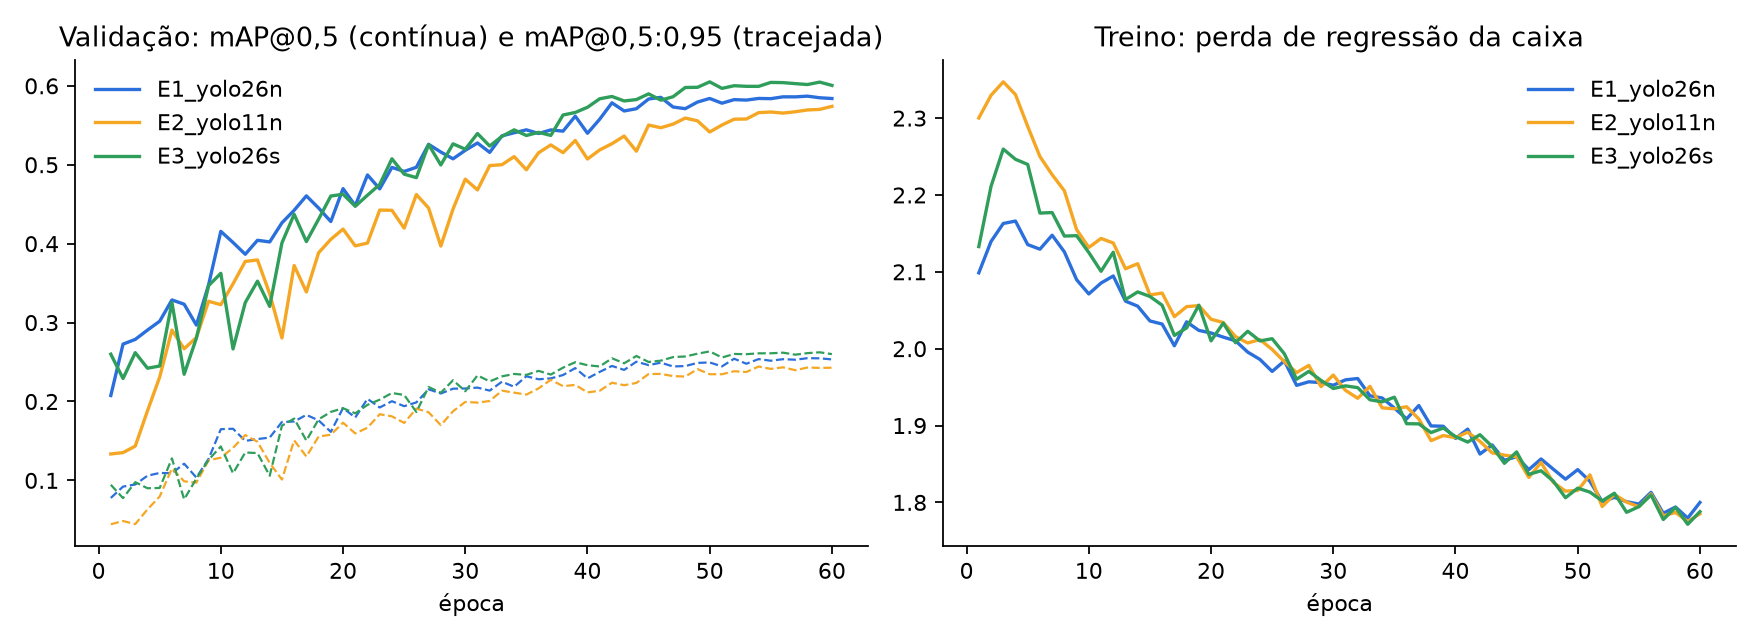

In [6]:
print((RAIZ / "configs" / "treino.yaml").read_text(encoding="utf-8"))
display(Image(filename=str(RES / "curvas_treino.png"), width=1000))

## 3. Comparação dos modelos e escolha do modelo de produção

,experimento,pesos_iniciais,parametros_M,treino_min,val_mAP50,val_mAP50_95,val_F1,limiar,teste_mAP50,teste_mAP50_95,teste_precisao,teste_revocacao,inferencia_ms_gpu
0,E1_yolo26n,yolo26n.pt,2.53,32.9,0.5878,0.2549,0.5867,0.305,0.5848,0.2589,0.6699,0.5264,3.154
1,E2_yolo11n,yolo11n.pt,2.60,34.4,0.5646,0.2442,0.5612,0.261,0.5612,0.2492,0.6337,0.5209,2.909
2,E3_yolo26s,yolo26s.pt,9.95,42.5,0.6042,0.2637,0.5918,0.295,0.5887,0.2603,0.6078,0.5560,4.728


**Modelo escolhido:** `E1_yolo26n` · limiar de confiança **0.305** (máximo F1 na validação) · regra: menor latência entre modelos a até 1.5 p.p. do melhor mAP50-95 de validação

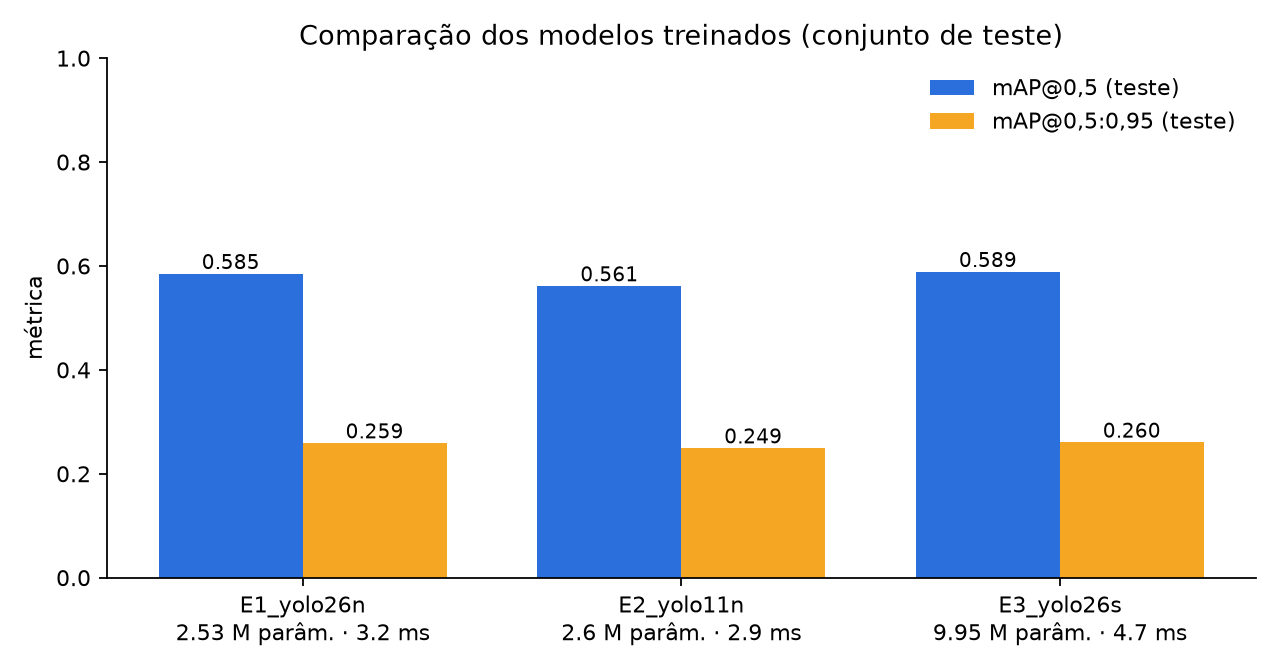

In [7]:
comp = pd.read_csv(RES / "comparacao_modelos.csv")
display(comp)
op = json.loads((RAIZ / "configs" / "operacao.json").read_text(encoding="utf-8"))
display(Markdown(f"**Modelo escolhido:** `{op['experimento']}` · limiar de confiança **{op['conf']:.3f}** "
                 f"(máximo F1 na validação) · regra: {op['regra_escolha']}"))
display(Image(filename=str(RES / "comparacao_modelos.png"), width=800))

## 4. Avaliação no conjunto de teste (imagens nunca vistas no treino nem na escolha do limiar)

,val,test
precisao,0.643705,0.669884
revocacao,0.533413,0.526374
mAP50,0.587811,0.584849
mAP50_95,0.254894,0.258915
melhor_f1,0.586723,0.594074
limiar_conf_melhor_f1,0.305305,0.324324
precisao_no_limiar,0.664797,0.699097
revocacao_no_limiar,0.52506,0.516484


**teste_BoxPR_curve.png**

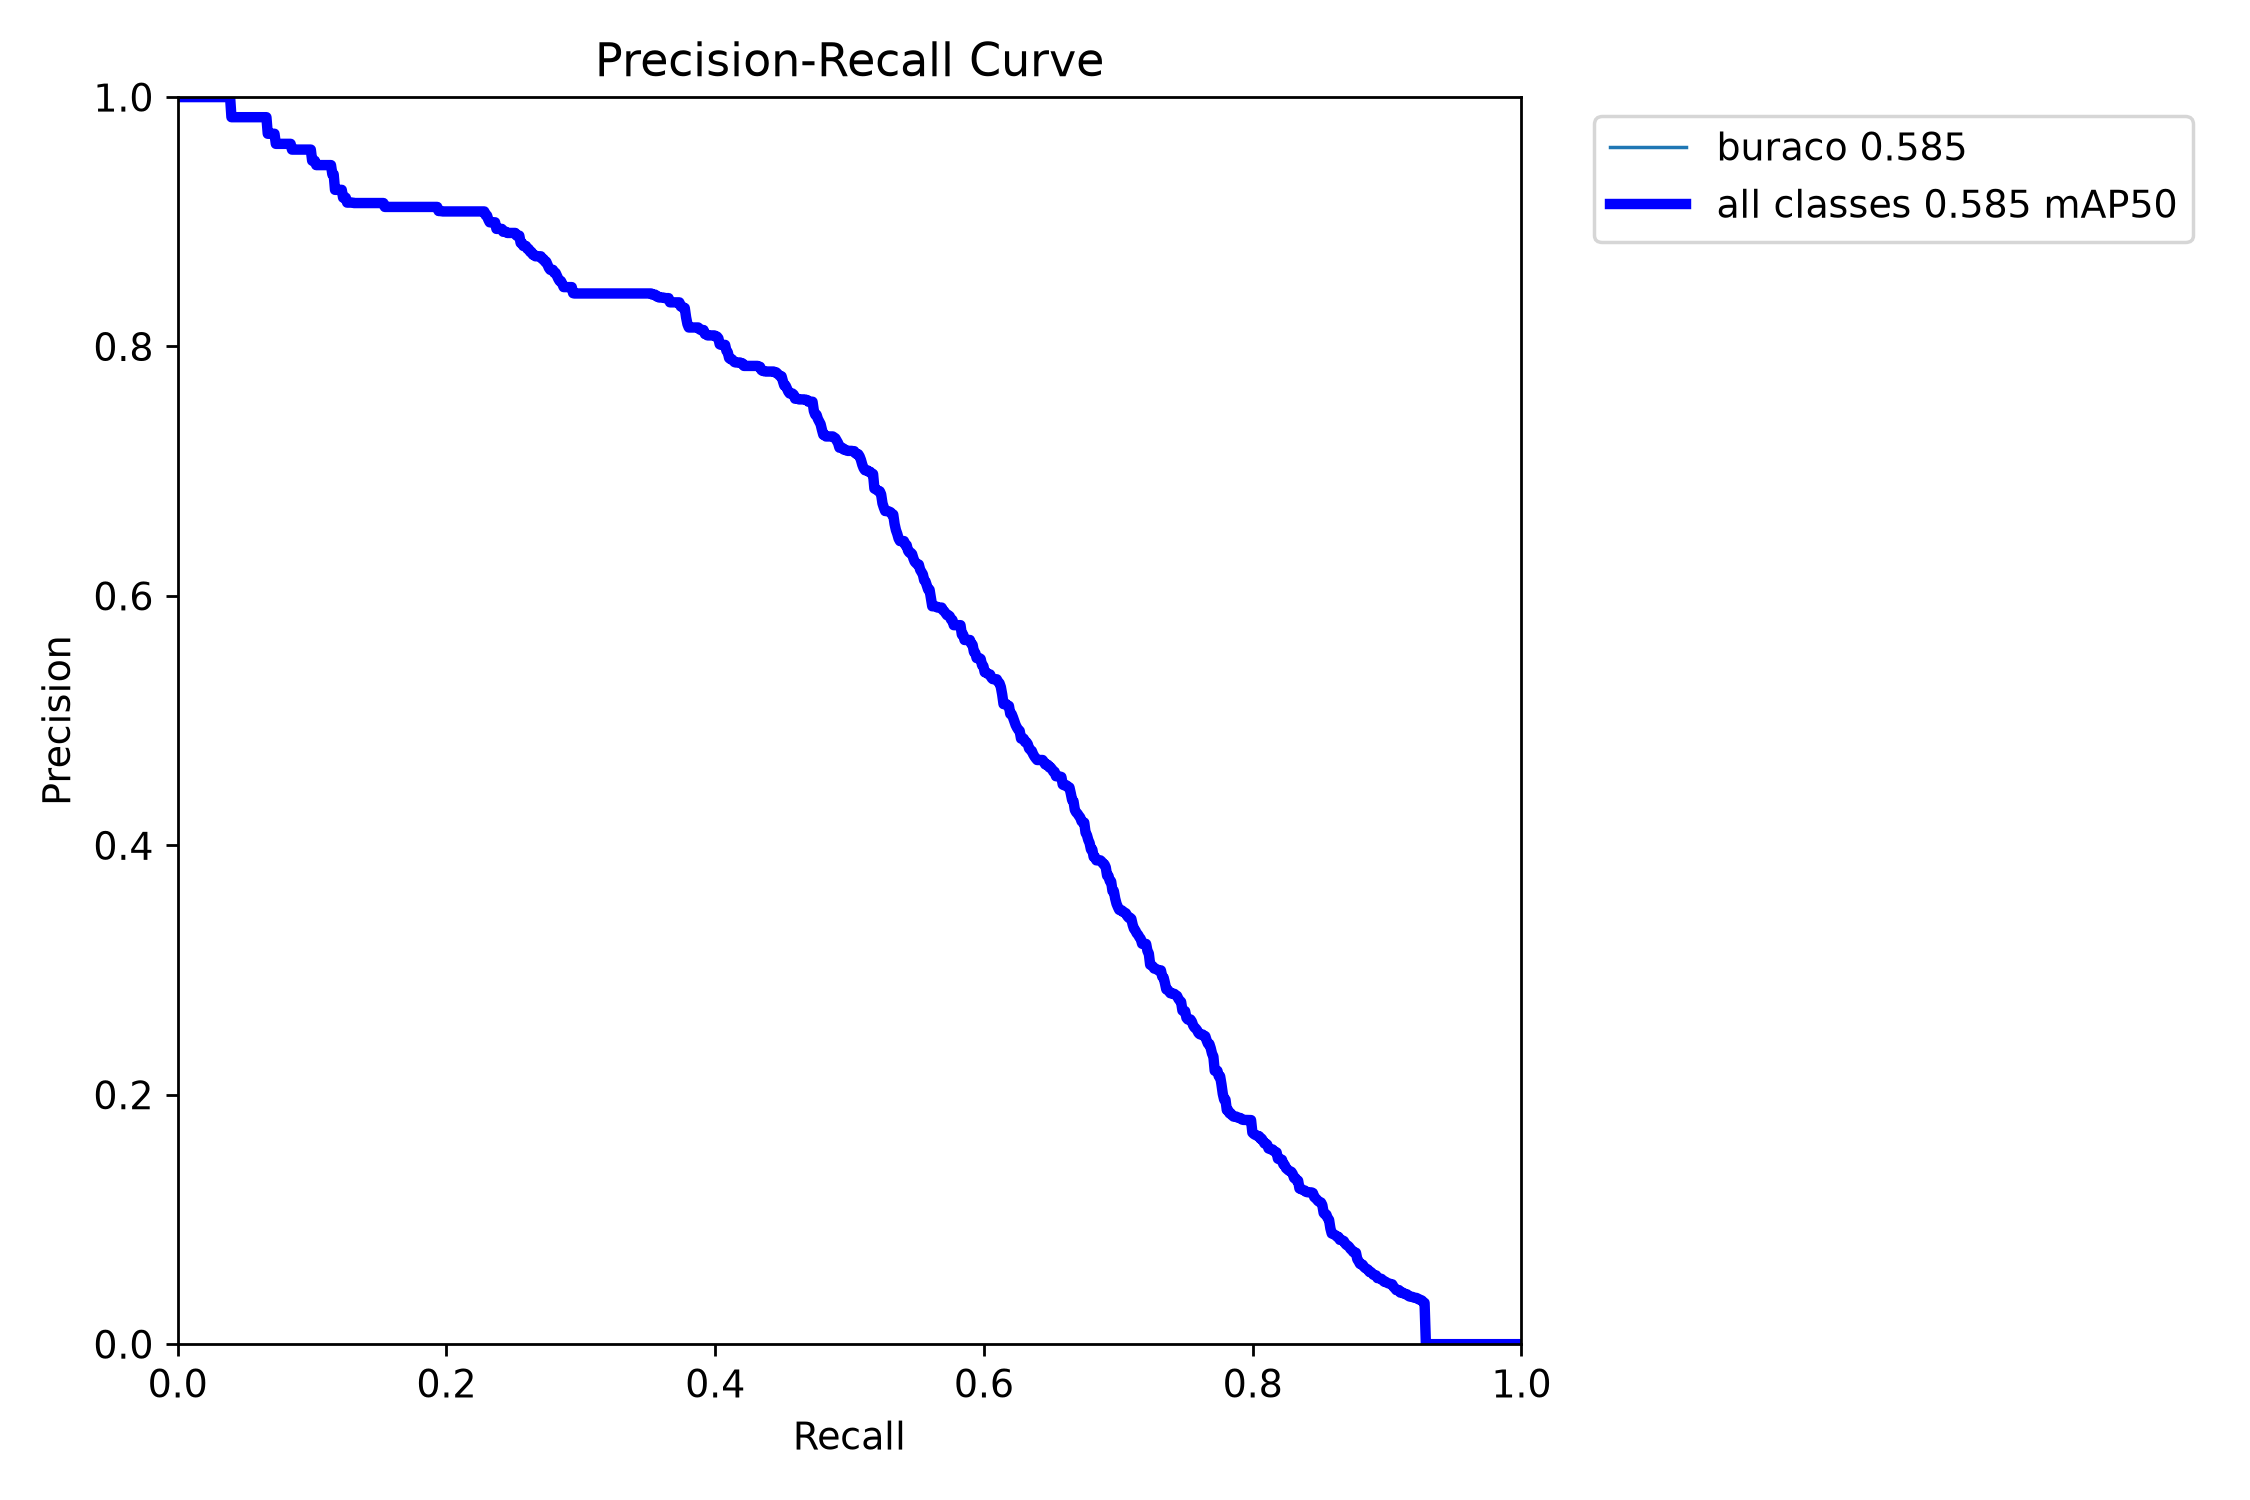

**teste_BoxF1_curve.png**

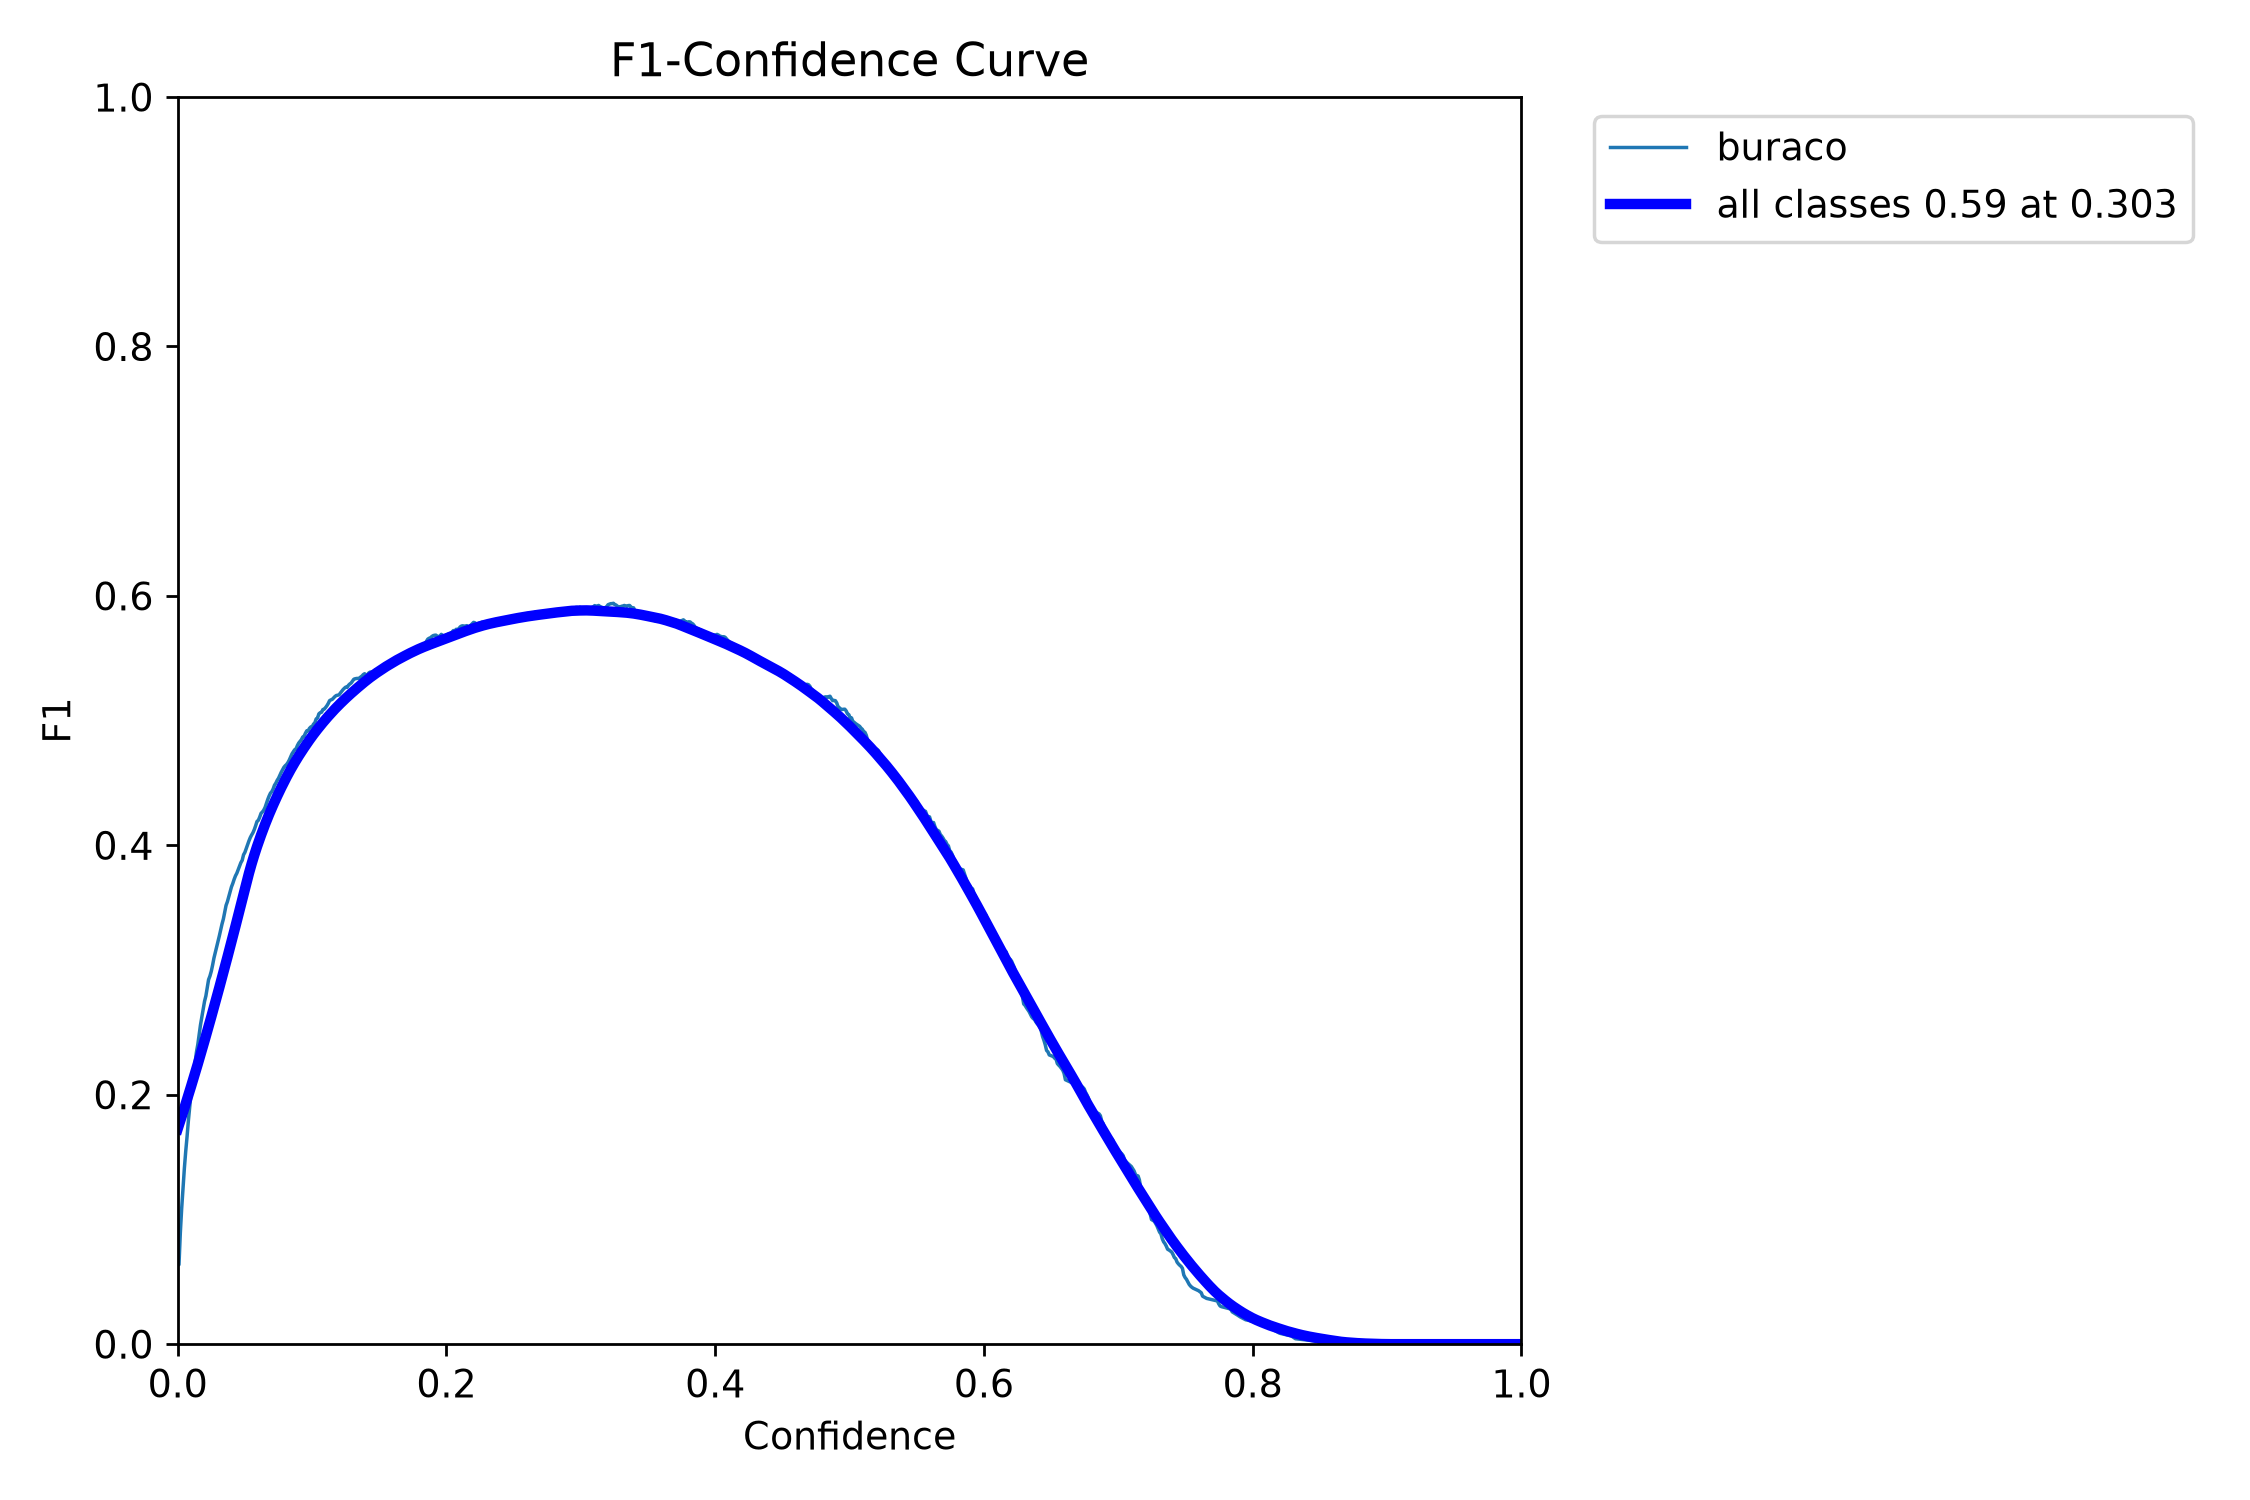

**teste_confusion_matrix_normalized.png**

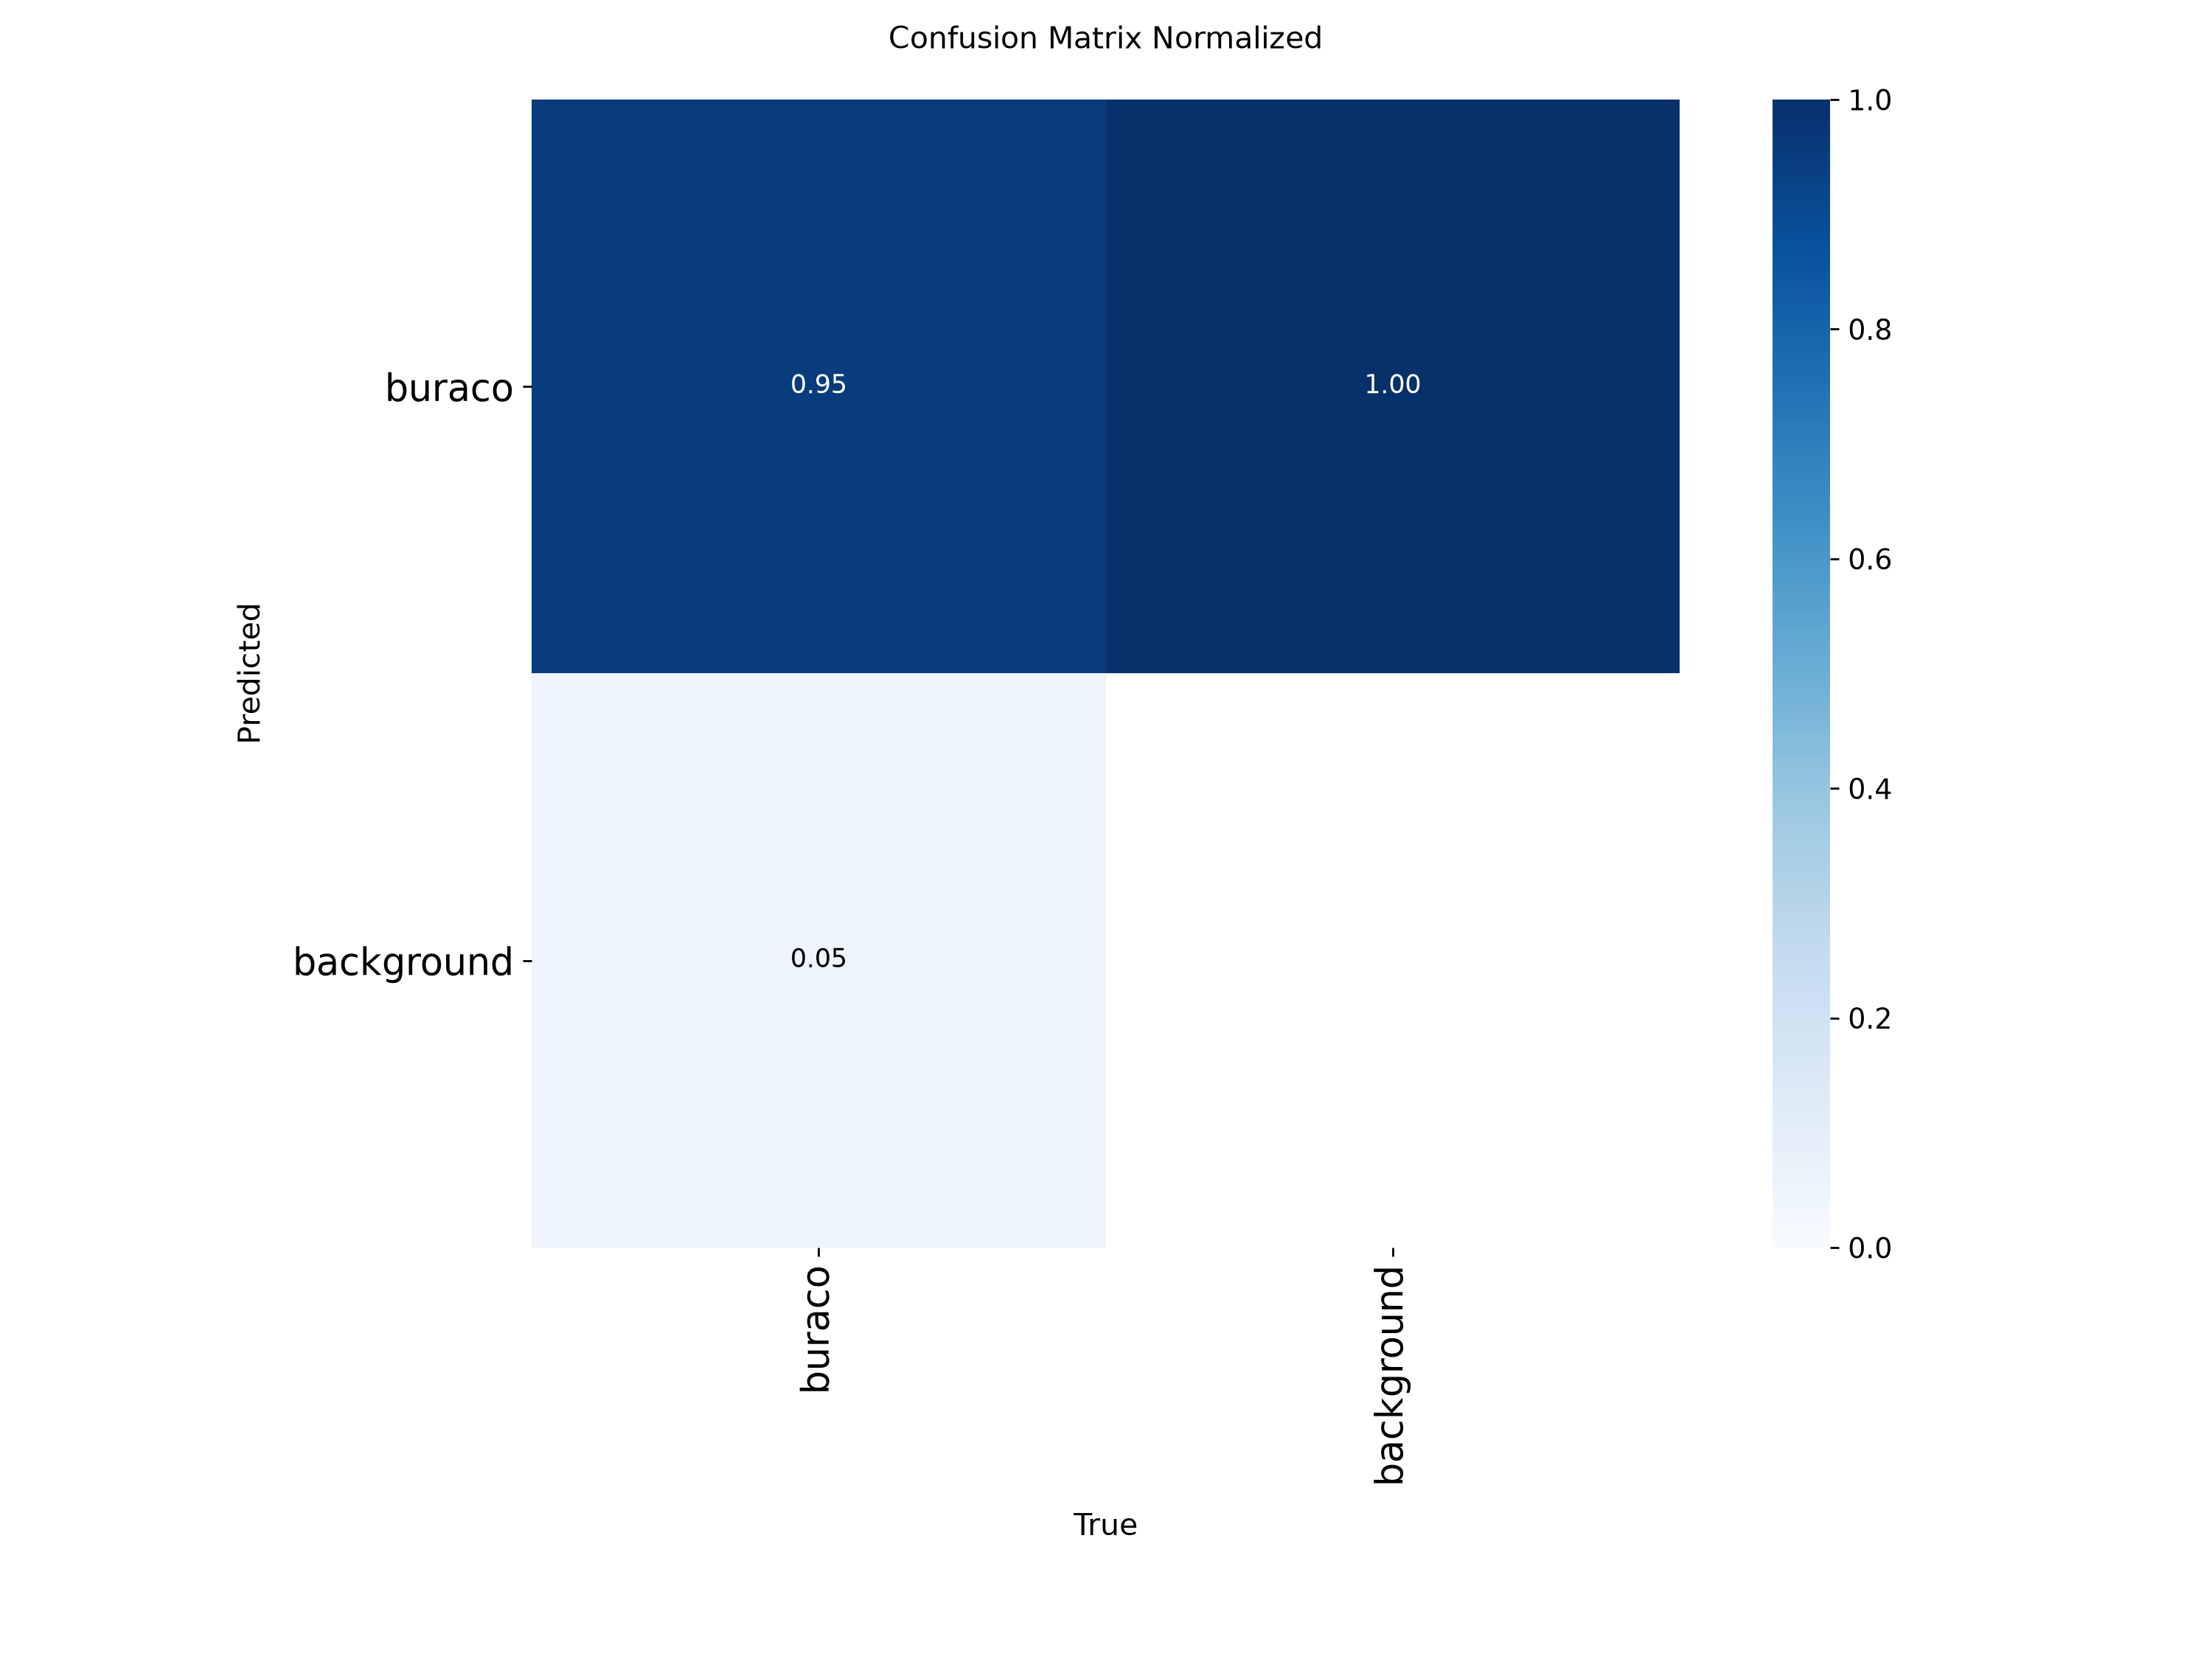

In [8]:
met = json.loads((RES / op["experimento"] / "metricas.json").read_text(encoding="utf-8"))
display(pd.DataFrame({k: met[k] for k in ("val", "test")}).drop(index=["velocidade_ms_por_imagem"], errors="ignore"))
for nome in ("teste_BoxPR_curve.png", "teste_BoxF1_curve.png", "teste_confusion_matrix_normalized.png"):
    f = RES / op["experimento"] / nome
    if f.exists():
        display(Markdown(f"**{nome}**")); display(Image(filename=str(f), width=620))

## 5. IA responsável: vieses e análise de erros

Precisão/revocação **no limiar de operação** por subgrupo (país de origem, iluminação em tercis de brilho) e revocação
por tamanho do buraco (critério COCO). Verde = buraco real detectado; azul = predição correta; vermelho = falso
positivo; magenta = buraco perdido.

,tp,fp,fn,precisao,revocacao,f1
geral,459.0,193.0,451.0,0.7040,0.5044,0.5877
país: China_MotorBike,29.0,2.0,1.0,0.9355,0.9667,0.9508
iluminação: média,126.0,53.0,117.0,0.7039,0.5185,0.5972
iluminação: clara,200.0,88.0,184.0,0.6944,0.5208,0.5952
país: Czech,20.0,10.0,26.0,0.6667,0.4348,0.5263
iluminação: escura,133.0,52.0,150.0,0.7189,0.4700,0.5684
país: India,197.0,101.0,266.0,0.6611,0.4255,0.5177
país: Japan,201.0,74.0,144.0,0.7309,0.5826,0.6484
país: United_States,12.0,6.0,14.0,0.6667,0.4615,0.5455


,buracos,detectados,revocacao
médio (32²–96²px),517.0,255.0,0.4932
pequeno (<32²px),210.0,107.0,0.5095
grande (>96²px),183.0,97.0,0.5301


,imagens,mAP50,mAP50_95
China_MotorBike,22.0,0.9856,0.5669
Czech,42.0,0.4722,0.1618
India,274.0,0.4991,0.2009
Japan,258.0,0.6700,0.3150
United_States,26.0,0.5335,0.3002


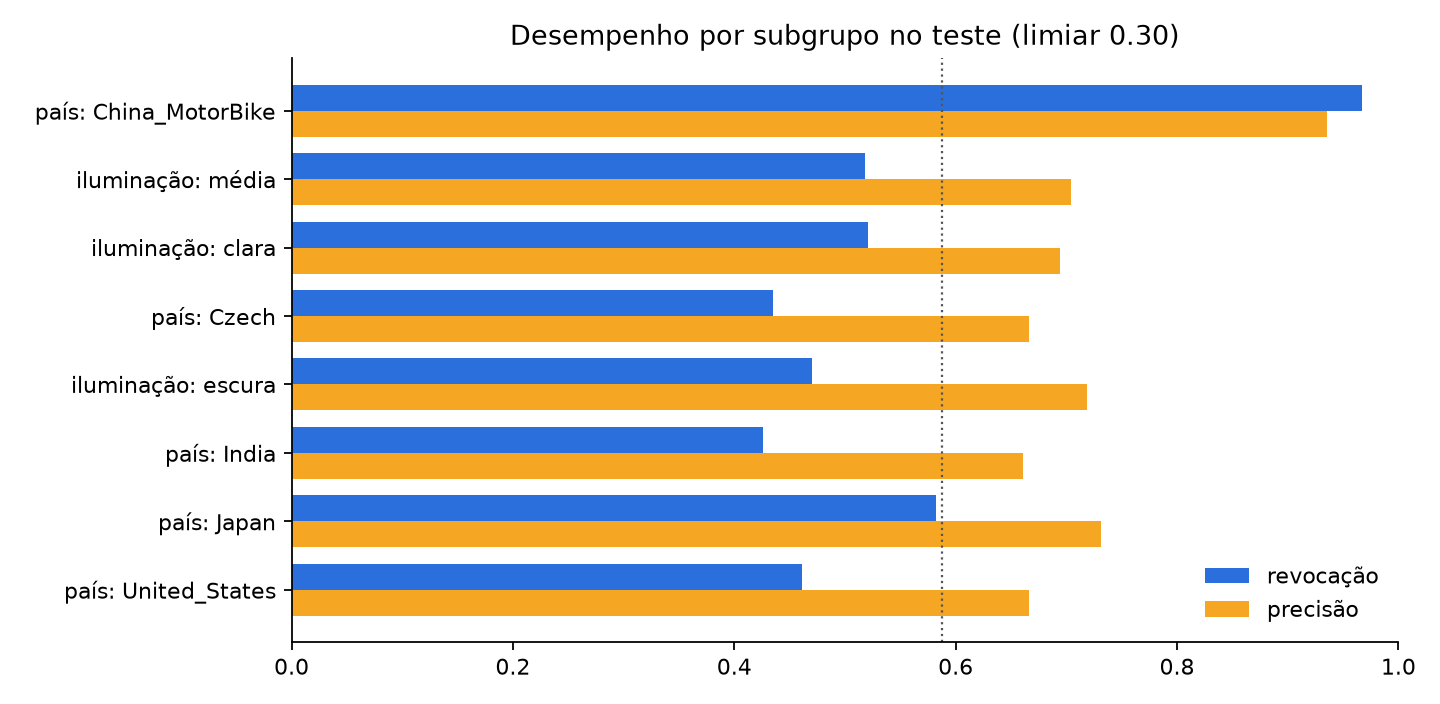

**acertos**

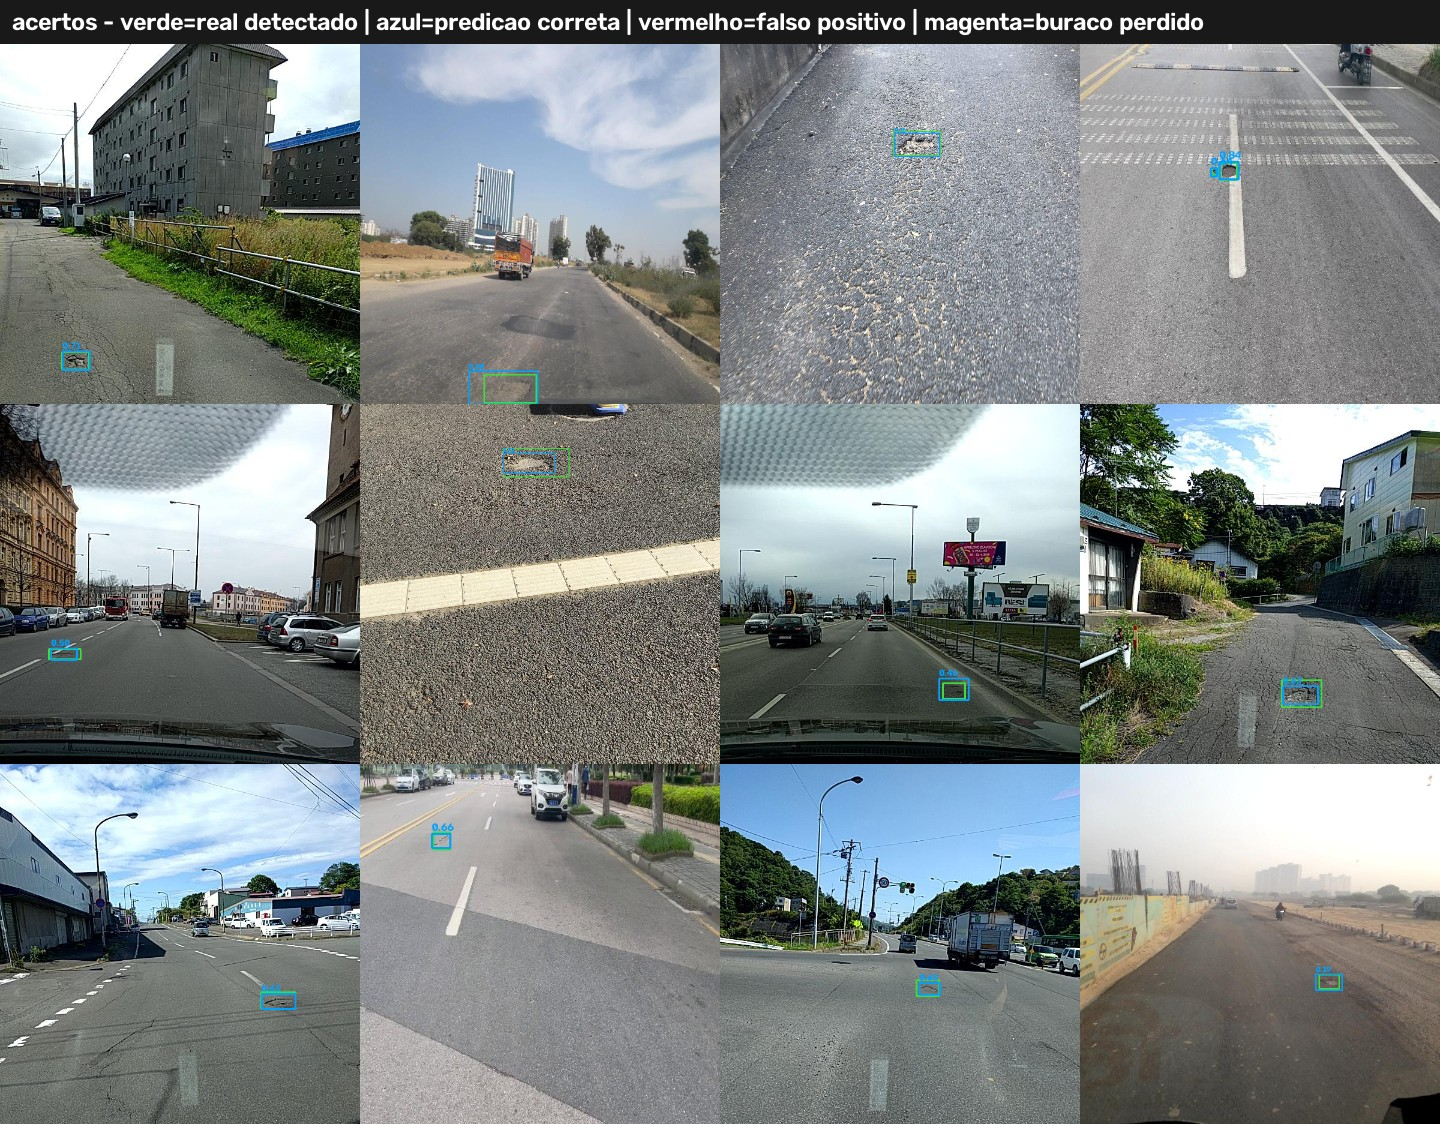

**falsos positivos**

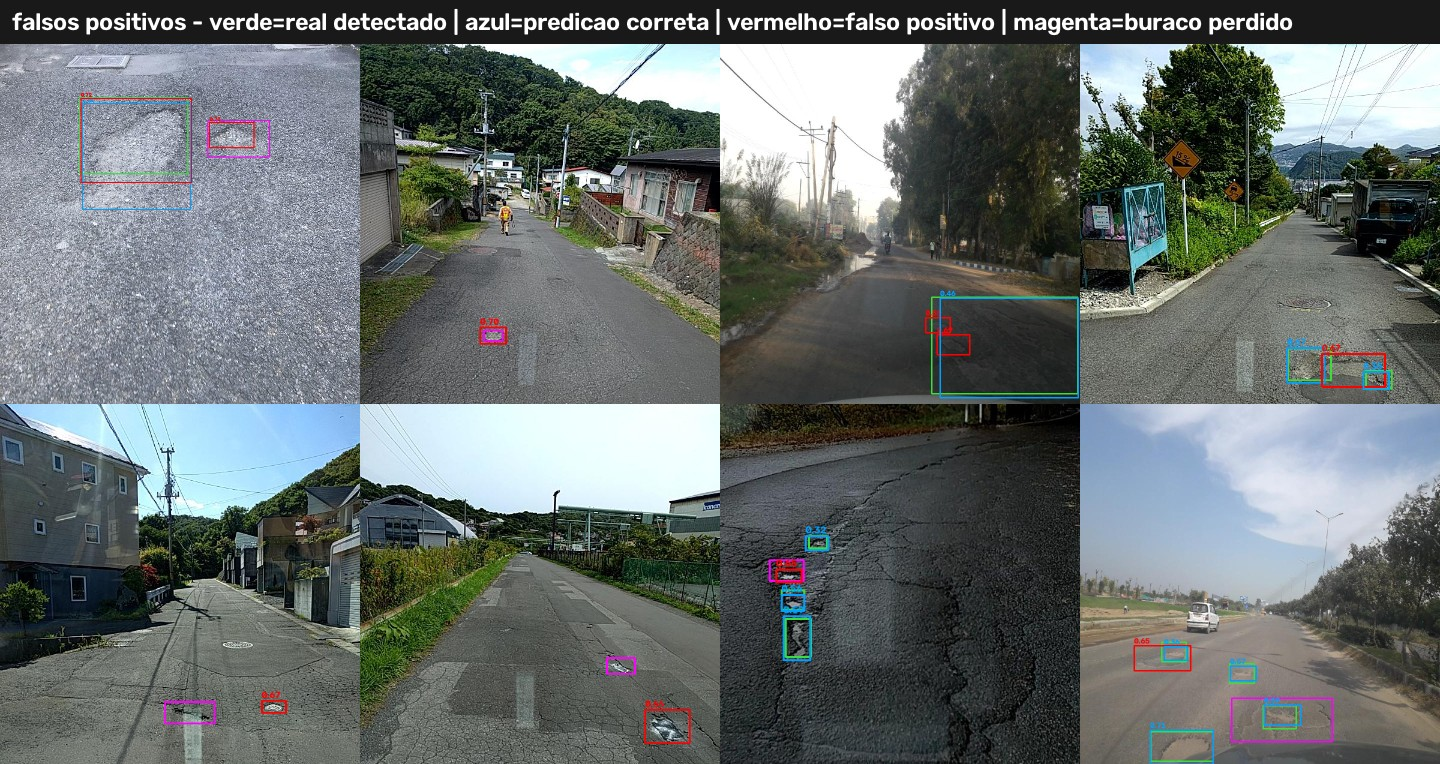

**falsos negativos**

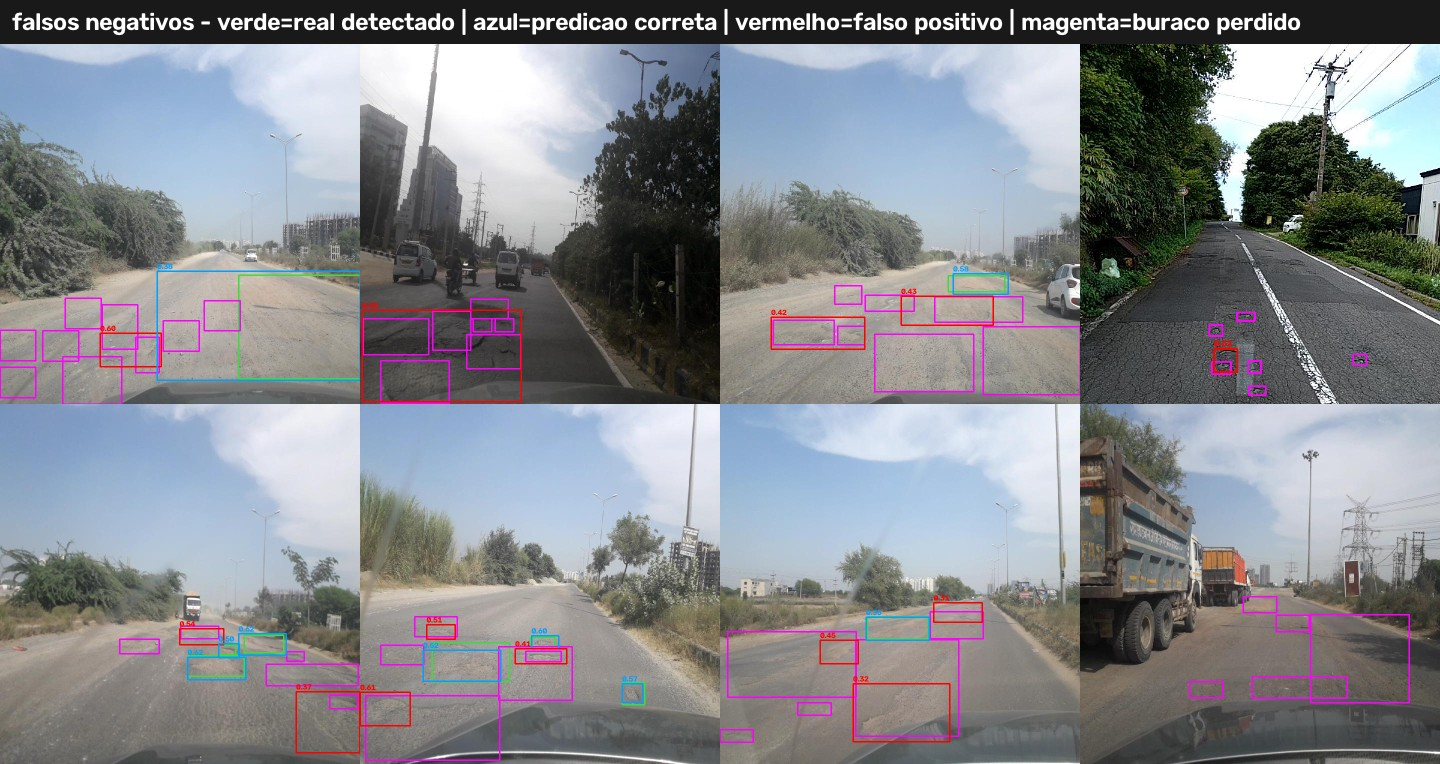

In [9]:
an = json.loads((RES / "analise_teste.json").read_text(encoding="utf-8"))
display(pd.DataFrame(an["grupos"]).T)
display(pd.DataFrame(an["revocacao_por_tamanho"]).T)
display(pd.DataFrame(an["ap_por_pais"]).T)
display(Image(filename=str(RES / "vieses_subgrupos.png"), width=850))
for n in ("acertos", "falsos_positivos", "falsos_negativos"):
    display(Markdown(f"**{n.replace('_', ' ')}**")); display(Image(filename=str(RES / f"exemplos_{n}.jpg"), width=1000))

## 6. Severidade (proxy) e inferência no modelo de produção

Índice = área relativa da caixa corrigida pela perspectiva de uma via plana; limiares = tercis no treino
(`configs/severidade.json`). É uma **priorização relativa**, não uma medida física.

{'metodo': 'tercis do índice de severidade nas caixas de treino', 'n_caixas': 4249, 'horizonte': 0.35, 'limiar_media': 0.00919, 'limiar_alta': 0.02956}


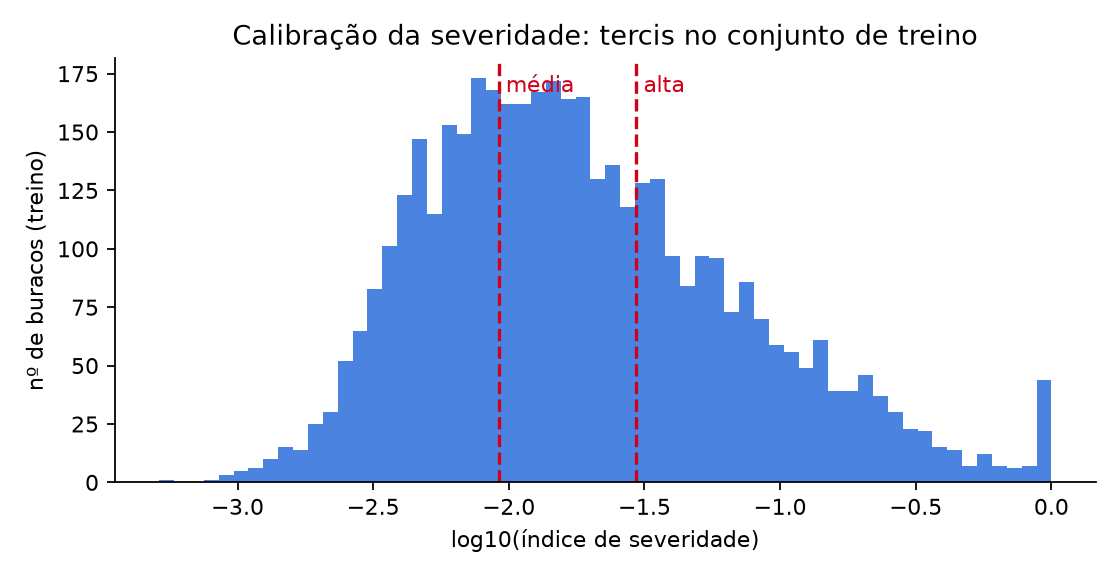

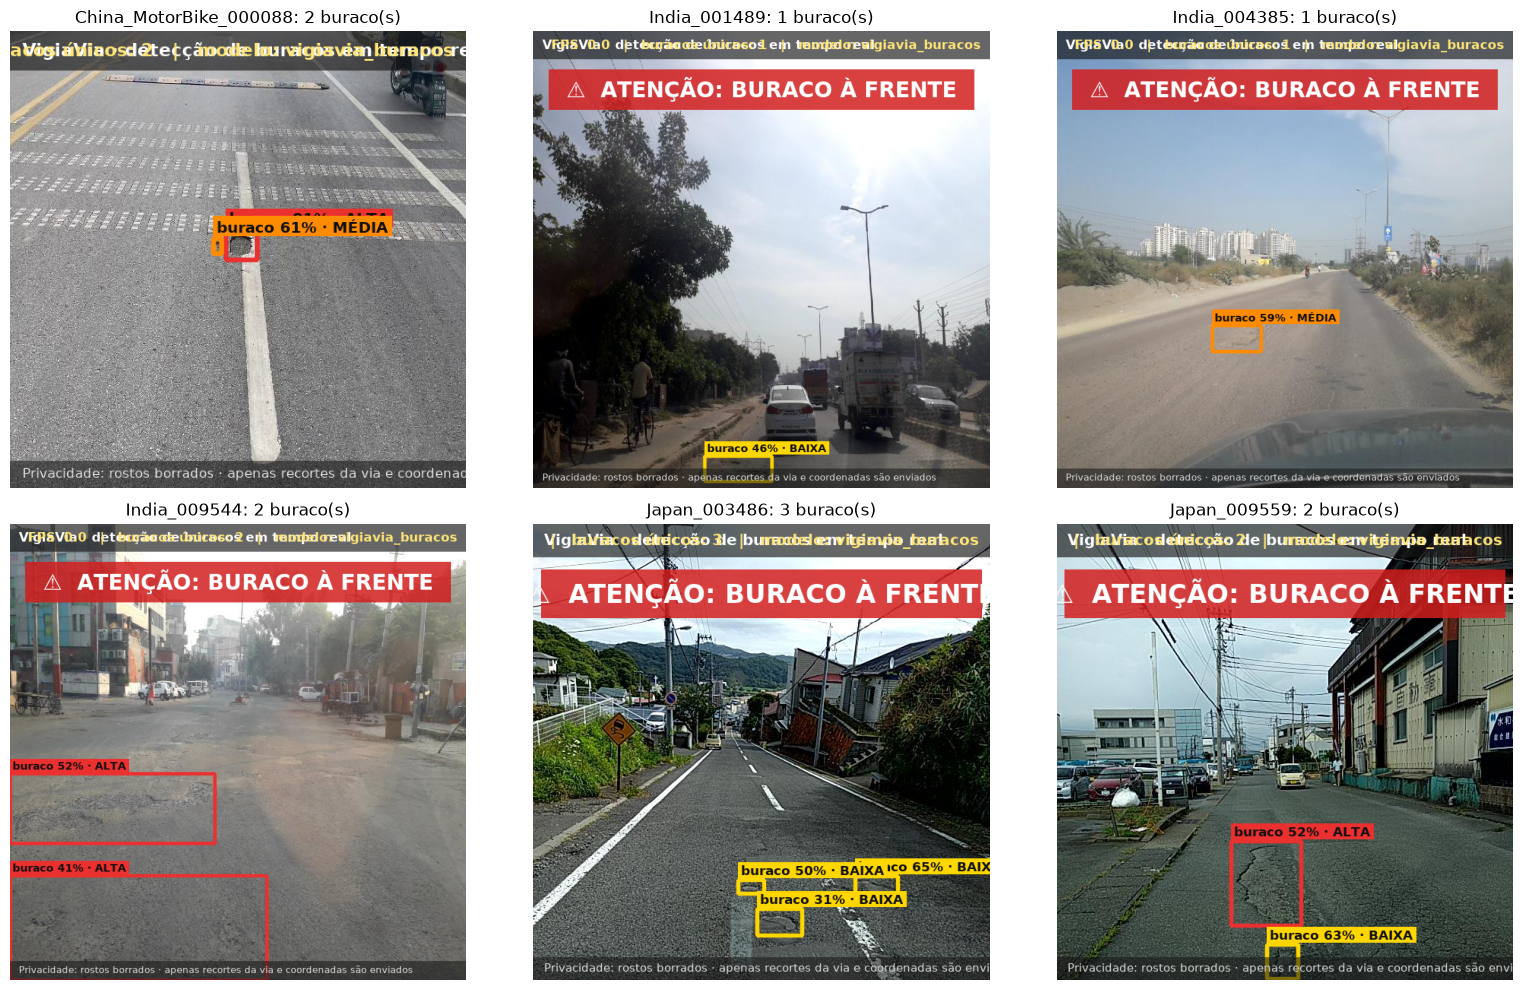

In [10]:
from vigiavia.detector import DetectorBuracos
from vigiavia import hud, config
print(json.loads((RAIZ / "configs" / "severidade.json").read_text(encoding="utf-8")))
display(Image(filename=str(RES / "calibracao_severidade.png"), width=700))
det = DetectorBuracos(config.pesos_padrao(), conf=config.conf_padrao())
com_buraco = set(man[(man.split == "test") & (man.n_buracos > 0)].arquivo)
testes = [p for p in sorted((DATA / "images" / "test").glob("*.jpg")) if p.name in com_buraco][::80][:6]
fig, axs = plt.subplots(2, 3, figsize=(16, 10))
for ax, p in zip(axs.ravel(), testes):
    im = cv2.imread(str(p)); d = det.detectar(im)
    vis = hud.desenhar(im, d, det.conf, 0, len(d), det.nome, mostrar_zona=False)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.set_title(f"{p.stem}: {len(d)} buraco(s)"); ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Tempo real: detecção + BoT-SORT + HUD de realidade aumentada

Vídeo real de São Paulo (Rua Sílvia, Bela Vista — Daniel Fraga, CC BY 3.0, Wikimedia Commons), **nunca visto no
treino**. Cada buraco recebe um ID; um evento só é emitido quando a trilha é confirmada (≥ 3 quadros e confiança ≥
limiar).

240 quadros · 29.3 ms/quadro (detecção+rastreamento) · trilhas: 12


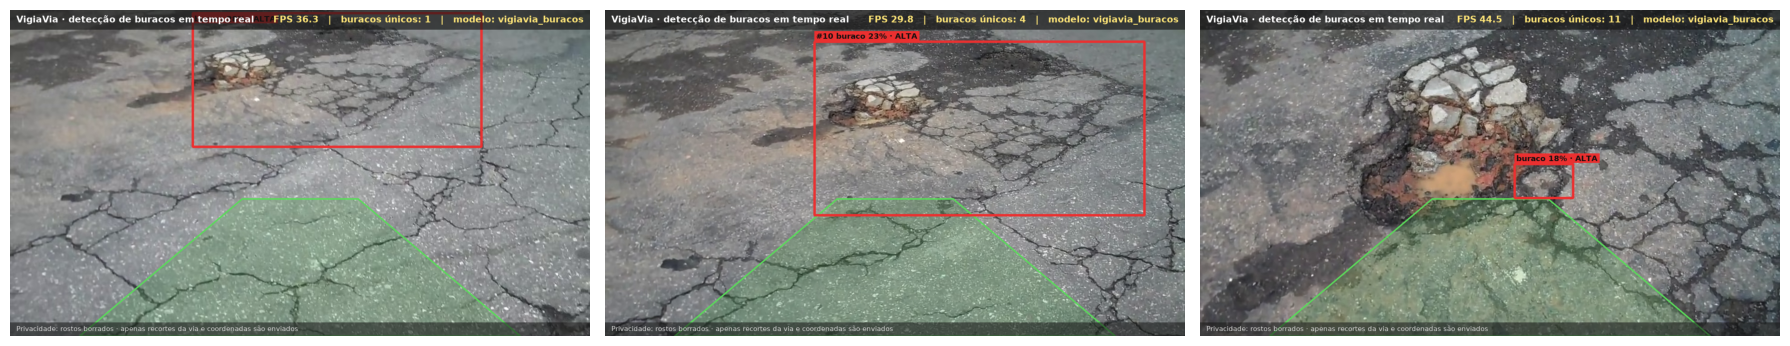

carros_no_buraco {'fonte': 'C:\\Users\\eduar\\AppData\\Local\\Temp\\claude\\5c076af41ba4acbc\\6e99c3b2-8eac-48d7-b7f2-d6d1e0f28f47\\scratchpad\\videos_fonte\\carros_no_buraco.webm', 'modelo': 'vigiavia_buracos', 'limiar': 0.305, 'quadros': 621, 'fps_fonte': 29.97, 'tempo_total_s': 44.1, 'ms_por_quadro_pipeline': 54.2, 'ms_p95': 76.1, 'fps_pipeline': 18.5, 'trilhas': 3, 'trilhas_duplicadas_suprimidas': 0, 'buracos_confirmados': 3}
estrada_com_agua {'fonte': 'C:\\Users\\eduar\\AppData\\Local\\Temp\\claude\\5c076af41ba4acbc\\6e99c3b2-8eac-48d7-b7f2-d6d1e0f28f47\\scratchpad\\videos_fonte\\estrada_com_agua.webm', 'modelo': 'vigiavia_buracos', 'limiar': 0.305, 'quadros': 869, 'fps_fonte': 30.0, 'tempo_total_s': 60.9, 'ms_por_quadro_pipeline': 54.7, 'ms_p95': 77.6, 'fps_pipeline': 18.3, 'trilhas': 22, 'trilhas_duplicadas_suprimidas': 2, 'buracos_confirmados': 15}
kumasi_pothole {'fonte': 'C:\\Users\\eduar\\AppData\\Local\\Temp\\claude\\5c076af41ba4acbc\\6e99c3b2-8eac-48d7-b7f2-d6d1e0f28f47\\s

In [11]:
import time
video = next((RAIZ / "demo" / "videos_fonte").glob("sp_*"), None) or next(Path(os.getenv("VIGIAVIA_VIDEOS", ".")).glob("sp_*"))
cap = cv2.VideoCapture(str(video)); det.reiniciar_rastreamento()
quadros, tempos, ids = [], [], set()
for i in range(240):
    ok, q = cap.read()
    if not ok: break
    t0 = time.perf_counter(); d = det.rastrear(q); tempos.append(time.perf_counter() - t0)
    ids |= {x.track_id for x in d if x.track_id is not None}
    if i in (60, 140, 220): quadros.append(hud.desenhar(q, d, det.conf, 1 / np.mean(tempos[-30:]), len(ids), det.nome))
cap.release()
print(f"{len(tempos)} quadros · {1000*np.mean(tempos[5:]):.1f} ms/quadro (detecção+rastreamento) · trilhas: {len(ids)}")
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, q in zip(axs, quadros): ax.imshow(cv2.cvtColor(q, cv2.COLOR_BGR2RGB)); ax.axis("off")
plt.tight_layout(); plt.show()
for f in sorted((RES / "tempo_real").glob("*.json")):
    r = json.loads(f.read_text(encoding="utf-8")); r.pop("creditos", None); print(f.stem, r)

## 8. Velocidade e exportação ONNX (CPU, celular e navegador)

,modelo,execucao,ms_media,ms_p95,fps
0,E1_yolo26n,PyTorch GPU FP16,16.13,20.11,62.0
1,E1_yolo26n,PyTorch GPU FP32,15.30,20.55,65.4
2,E1_yolo26n,PyTorch CPU FP32,35.54,38.07,28.1
3,E2_yolo11n,PyTorch GPU FP16,16.14,19.04,62.0
4,E2_yolo11n,PyTorch GPU FP32,12.88,14.30,77.6
5,E2_yolo11n,PyTorch CPU FP32,35.35,36.82,28.3
6,E3_yolo26s,PyTorch GPU FP16,14.91,15.59,67.1
7,E3_yolo26s,PyTorch GPU FP32,14.07,14.62,71.1
8,E3_yolo26s,PyTorch CPU FP32,71.99,76.09,13.9
9,produção (ONNX),ONNX Runtime CPU,25.56,28.16,39.1


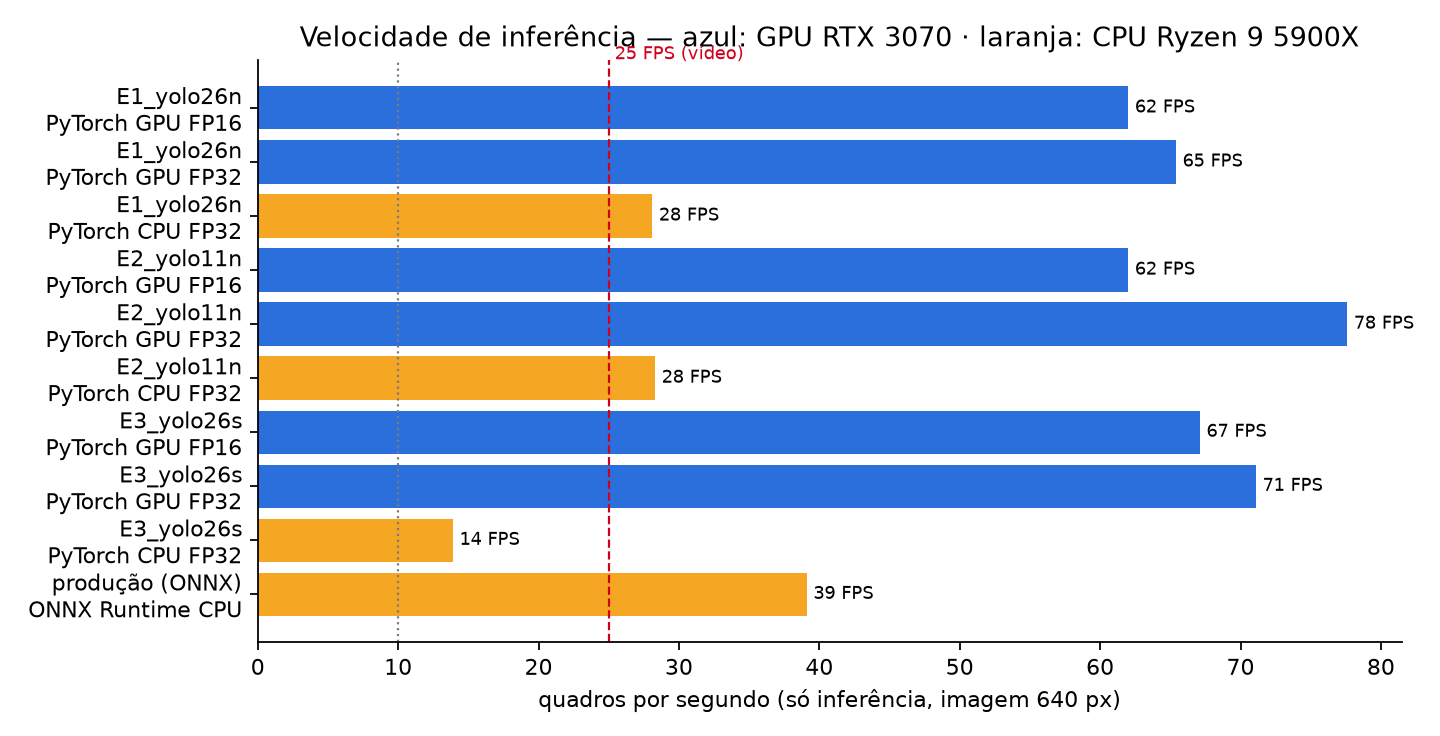

Paridade PyTorch x ONNX: {'pytorch_gpu': {'mAP50': 0.5848, 'mAP50_95': 0.2589, 'ms_inferencia': 2.33}, 'onnx_cpu_fim_a_fim': {'mAP50': 0.542, 'mAP50_95': 0.2326, 'ms_inferencia': 20.72}, 'onnx_cpu_com_nms': {'mAP50': 0.5816, 'mAP50_95': 0.2521, 'ms_inferencia': 20.0}, 'variante_escolhida': 'com_nms', 'onnx_cpu': {'mAP50': 0.5816, 'mAP50_95': 0.2521, 'ms_inferencia': 20.0}}
Entrada: images [1, 3, 640, 640] | Saída: output0 [1, 5, 8400]


In [12]:
display(pd.read_csv(RES / "velocidade.csv"))
display(Image(filename=str(RES / "velocidade.png"), width=850))
print("Paridade PyTorch x ONNX:", json.loads((RES / "paridade_onnx.json").read_text()))
import onnxruntime as ort
s = ort.InferenceSession(str(RAIZ / "modelos" / "vigiavia_buracos.onnx"), providers=["CPUExecutionProvider"])
print("Entrada:", s.get_inputs()[0].name, s.get_inputs()[0].shape, "| Saída:", s.get_outputs()[0].name, s.get_outputs()[0].shape)

## 9. Integração com o MVP (API FastAPI)

Contrato: `POST /v1/deteccoes` (imagem → caixas, nada é armazenado) e `POST /v1/relatos` (evento → fila da zeladoria,
com deduplicação geográfica de 15 m). Abaixo, a API é exercitada em processo com o `TestClient`.

In [13]:
import base64, tempfile
os.environ["VIGIAVIA_DB"] = str(Path(tempfile.mkdtemp()) / "demo.db")
from fastapi.testclient import TestClient
sys.path.insert(0, str(RAIZ)); import api.main as apimain
apimain.BANCO = Path(os.environ["VIGIAVIA_DB"])
with TestClient(apimain.app) as c:
    print(c.get("/health").json())
    img = testes[0]
    r = c.post("/v1/deteccoes", files={"imagem": (img.name, img.read_bytes(), "image/jpeg")}).json()
    print("Detecções:", r["quantidade"], "| inferência:", r["tempo_inferencia_ms"], "ms"); display(pd.DataFrame(r["deteccoes"]))
    corpo = {"lat": -23.560345, "lon": -46.650508, "severidade": "media", "confianca_max": 0.81, "origem": "cidadao"}
    print(c.post("/v1/relatos", json=corpo).json()["mensagem"])
    print(c.post("/v1/relatos", json={**corpo, "lat": -23.560390, "severidade": "alta"}).json()["mensagem"])
    display(pd.DataFrame(c.get("/v1/relatos").json()["relatos"])[["severidade", "confirmacoes", "prioridade", "status"]])

C:\Users\eduar\AppData\Local\Temp\claude\5c076af41ba4acbc\6e99c3b2-8eac-48d7-b7f2-d6d1e0f28f47\scratchpad\venv-cv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


{'status': 'ok', 'versao': '1.0.0', 'modelo': 'vigiavia_buracos', 'limiar_confianca': 0.305, 'raio_deduplicacao_m': 15.0}
Detecções: 2 | inferência: 22.0 ms


,x1,y1,x2,y2,confianca,severidade,indice_severidade,area_relativa,na_trajetoria,classe
0,242.2,222.1,277.3,256.5,0.8056,alta,0.08529,0.00460,False,buraco
1,228.2,232.9,237.8,249.6,0.6078,media,0.01373,0.00062,False,buraco


Relato criado e enviado para validação da zeladoria
Buraco já registrado a 5 m — confirmação adicionada


,severidade,confirmacoes,prioridade,status
0,alta,2,6.0,pendente


## Conclusões

* O detector treinado atende ao requisito de **tempo real** em GPU e em CPU (ONNX), e a exportação ONNX preserva a
  precisão — o mesmo modelo roda no servidor, no notebook e no navegador do celular.
* O rastreamento converte centenas de quadros em **um relato por buraco**, e a API junta relatos próximos: isso ataca
  diretamente o problema dos chamados duplicados relatado pela Prefeitura de São Paulo.
* Os principais limites são **buracos pequenos/distantes** e o **viés de domínio** (dados de Japão/Índia/China).
  Próximo passo: coletar imagens brasileiras pelo próprio app (com consentimento) e retreinar, mantendo a validação
  humana antes de qualquer ordem de serviço.